# 02 · Quality control: low-quality cells, doublets and genes

A droplet-based library contains, besides intact single cells,
**(i)** damaged/dying cells (few genes, high mitochondrial fraction because
cytoplasmic mRNA leaks out while mitochondrial transcripts are retained),
**(ii)** droplets with ambient RNA only, and **(iii)** doublets (two cells in
one droplet). Each artefact can create spurious clusters, so it is removed
before any biological interpretation.

**Approach**
1. per-cell metrics: library size, detected genes, % mitochondrial, % ribosomal,
   % haemoglobin, % counts in the top-20 genes;
2. per-library outlier detection with median ± *n*·MAD (robust to the
   library-to-library differences in depth seen in Notebook 01), checked
   against cell identity so that QC does not remove whole cell types;
3. doublet detection with **scDblFinder** (primary) and **Scrublet** (secondary);
4. removal of genes detected in fewer than 10 cells.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from upsetplot import UpSet, from_indicators

from ipfatlas import doublets, qc
from ipfatlas.config import rscript, setup
from ipfatlas.plotting import CONDITION_COLORS, figsize, panel_label, save_figure, set_style
from ipfatlas.utils import log, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "02_qc"
TAB = P.tables / "02_qc"
QC = cfg["qc"]

adata = sc.read_h5ad(P.interim / "discovery_raw.h5ad")
adata

AnnData object with n_obs × n_vars = 220213 × 33694
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex'
    var: 'gene_symbol'

## 1. QC metrics

In [2]:
qc.compute_qc_metrics(adata, layer=None)
write_table(qc.qc_summary(adata), TAB / "qc_metrics_per_library_before")
adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb",
           "pct_counts_in_top_20_genes"]].describe().round(1)

,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,pct_counts_in_top_20_genes
count,220213.0,220213.0,220213.0,220213.0,220213.0,220213.0
mean,5301.5,1535.2,11.2,12.7,0.5,29.2
std,6303.3,1212.5,16.7,8.1,6.2,16.4
min,500.0,15.0,0.0,0.0,0.0,7.8
25%,1087.0,536.0,3.7,6.9,0.0,19.9
50%,2831.0,1166.0,5.9,11.5,0.0,24.4
75%,7156.0,2262.0,10.3,17.1,0.0,31.1
max,87535.0,8768.0,99.9,62.9,97.2,100.0


### Choosing the hard floors
Lung libraries mix very large cells (alveolar macrophages, >10,000 UMIs) with
very small ones (lymphocytes), so per-library MADs are wide and the MAD rule
alone barely removes low-capture barcodes. Barcodes binned by detected genes
show that those with <500 genes have a median of only ~640 UMIs (vs. ~1,160 at
500-750 genes) while their mitochondrial fraction is normal - the profile of
droplets dominated by ambient RNA rather than of damaged cells. We therefore set
hard floors of **500 genes and 1,000 UMIs**: stricter than Cell Ranger's call,
but gentler than the 1,000-gene cut-off of the original study, which removes
small immune cells.

In [3]:
bins = [0, 300, 500, 750, 1000, 1500, 2000, np.inf]
gb = pd.cut(adata.obs["n_genes_by_counts"], bins, right=False)
gene_bins = adata.obs.groupby(gb, observed=True).agg(
    barcodes=("total_counts", "size"),
    median_umis=("total_counts", "median"),
    median_pct_mito=("pct_counts_mt", "median"),
    fraction_kept_by_authors=("author_qc_pass", "mean")).round(2)
write_table(gene_bins, TAB / "barcodes_by_detected_genes")
gene_bins

,barcodes,median_umis,median_pct_mito,fraction_kept_by_authors
n_genes_by_counts,,,,
"[0.0, 300.0)",12200,771.0,73.120003,0.00
"[300.0, 500.0)",38053,637.0,5.220000,0.00
"[500.0, 750.0)",26669,1164.0,6.470000,0.00
"[750.0, 1000.0)",20903,1832.0,6.080000,0.00
"[1000.0, 1500.0)",32974,2943.0,5.650000,0.92
"[1500.0, 2000.0)",23863,4742.0,5.500000,0.94
"[2000.0, inf)",65551,10658.0,5.690000,0.94


## 2. Distributions per library
Libraries are ordered by diagnosis; dashed lines mark the hard floors.

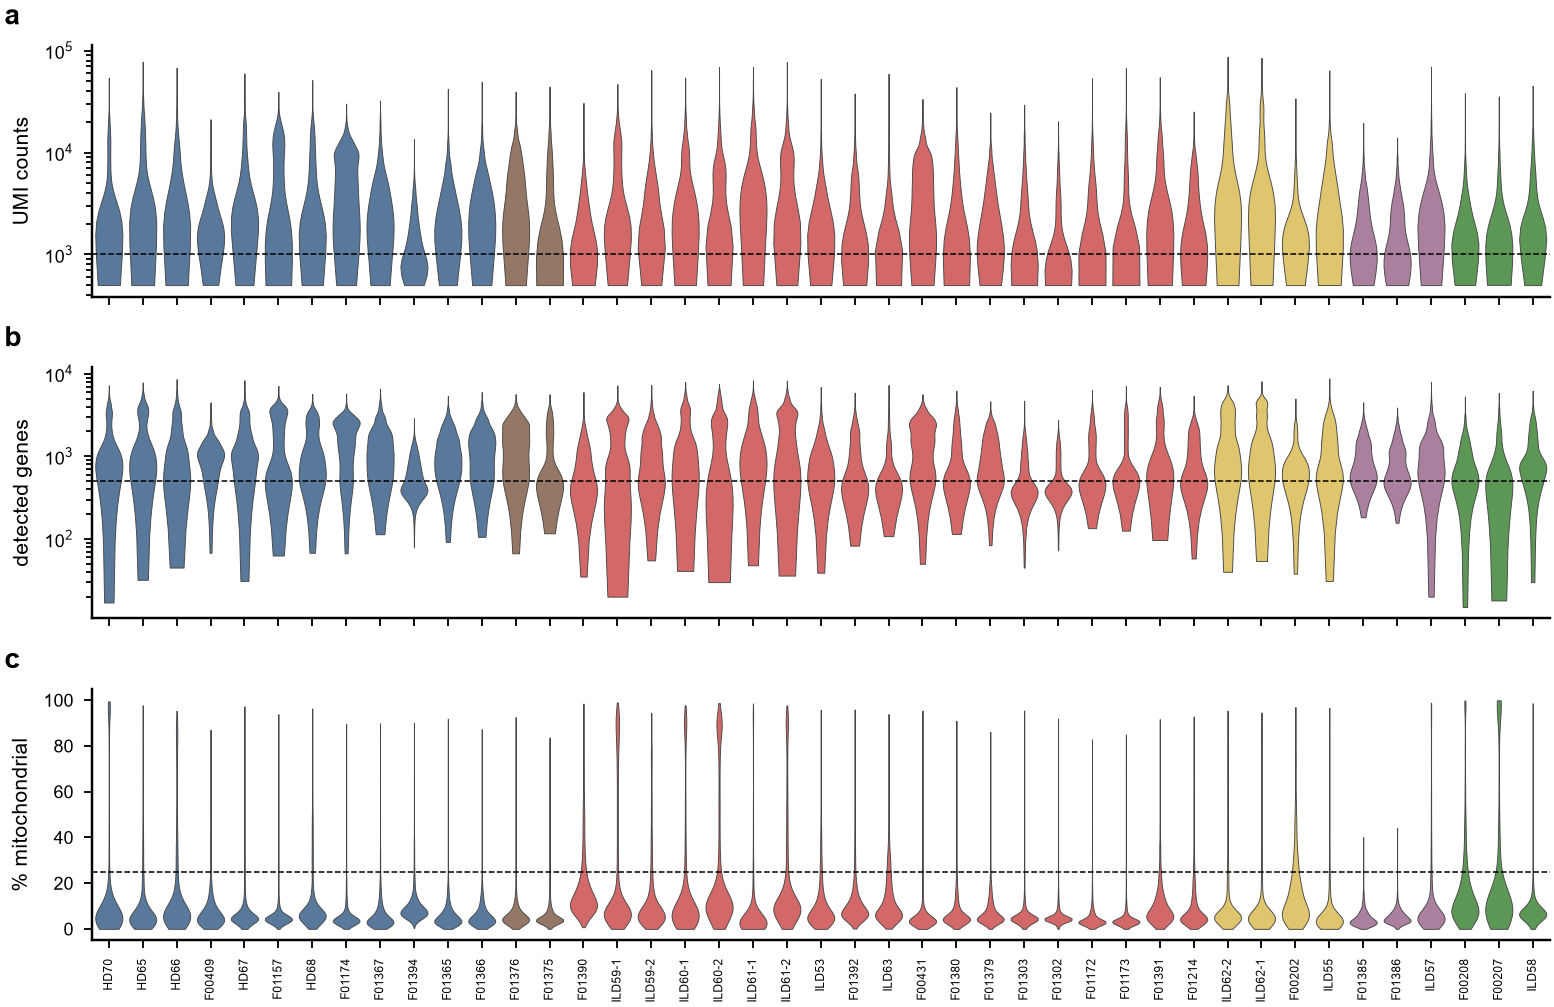

In [4]:
order = (adata.obs.groupby("library_id", observed=True)["diagnosis"].first()
         .sort_values().index.tolist())
pal = {lib: CONDITION_COLORS.get(dx, "grey")
       for lib, dx in adata.obs.groupby("library_id", observed=True)["diagnosis"].first().items()}

fig, axes = plt.subplots(3, 1, figsize=figsize(183, 120), sharex=True)
for ax, col, lab, log_y in [
    (axes[0], "total_counts", "UMI counts", True),
    (axes[1], "n_genes_by_counts", "detected genes", True),
    (axes[2], "pct_counts_mt", "% mitochondrial", False),
]:
    sns.violinplot(data=adata.obs, x="library_id", y=col, order=order, hue="library_id", palette=pal,
                   inner=None, linewidth=0.3, cut=0, density_norm="width", ax=ax, legend=False)
    ax.set_ylabel(lab)
    ax.set_xlabel("")
    if log_y:
        ax.set_yscale("log")
axes[0].axhline(QC["min_counts"], ls="--", lw=0.5, color="black")
axes[1].axhline(QC["min_genes"], ls="--", lw=0.5, color="black")
axes[2].axhline(QC["max_pct_mito"], ls="--", lw=0.5, color="black")
axes[2].tick_params(axis="x", rotation=90, labelsize=4)
for a, l in zip(axes, "abc"):
    panel_label(a, l, x=-0.06)
fig.tight_layout()
save_figure(fig, "S2_qc_violins_per_library", FIG)
plt.show()

## 3. Per-library MAD outlier detection

In [5]:
thr = qc.flag_outliers(adata, QC, groupby="library_id")
write_table(thr.round(2), TAB / "qc_thresholds_per_library")
flag_cols = ["outlier_counts", "outlier_genes", "outlier_top20", "outlier_mito", "outlier_hard"]
print(adata.obs[flag_cols + ["qc_fail"]].sum())
thr.sort_values("pct_fail", ascending=False).head(10)

outlier_counts     2252
outlier_genes      6958
outlier_top20     19904
outlier_mito      28630
outlier_hard      58096
qc_fail           72678
dtype: int64


,n_barcodes,counts_low,counts_high,genes_low,genes_high,mito_max_pct,n_fail,pct_fail
library_id,,,,,,,,
F01173,8069,103.276756,9134.077148,111.784771,3298.204301,15.000000,5806,71.954393
F01302,6342,77.363045,12658.234375,127.585359,1731.576730,15.000000,3793,59.807632
ILD63,7538,84.392967,16304.796875,74.793450,3677.207019,21.502993,4293,56.951446
F00207,1165,121.461647,13503.605469,56.131009,5948.290991,25.000000,656,56.309013
F01303,5596,31.482063,70101.710938,72.765027,4442.243832,15.000000,2757,49.267334
F01172,6141,23.463593,136742.593750,42.520414,22701.817190,15.000000,2706,44.064485
F01380,4010,19.217949,233657.546875,43.240065,25636.959725,15.000000,1745,43.516209
F01375,4532,10.705131,499912.562500,28.718710,42699.440473,15.000000,1930,42.586055
F01394,9619,131.110458,13937.709961,118.349782,3528.130872,15.000000,4015,41.740306


### QC must not remove biology
MAD thresholds assume that a metric's spread is technical. For the % of counts
in the top-20 genes this is false: cells whose transcriptome is dominated by a
few secretory products - plasma cells (immunoglobulins), goblet and club cells
(MUC5B, SCGB1A1, SCGB3A1), AT2 cells (SFTPC) - are "low-complexity" by biology.
For the cells the original authors annotated, the table shows the fraction
flagged by each criterion. The top-20 criterion flags most plasma cells and
about half of the secretory cells, so it is **reported but not used for
filtering**. For the same reason the mitochondrial threshold has a floor of
15 %: mitochondria-rich ciliated cells lost 18 % of their cells with a 10 % floor.

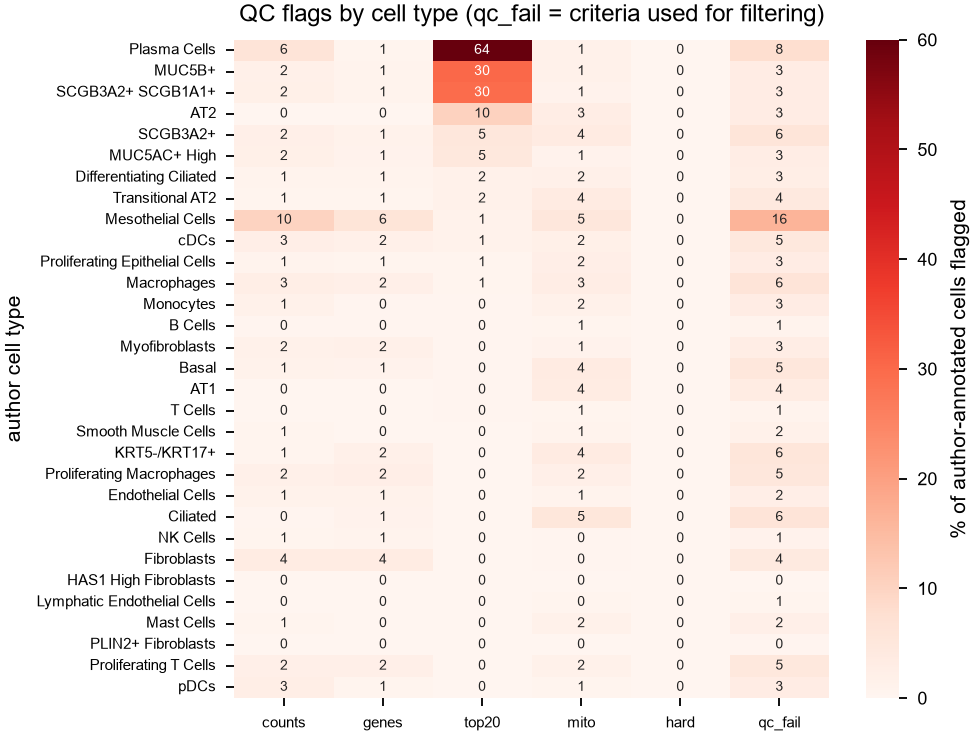

,outlier_counts,outlier_genes,outlier_top20,outlier_mito,outlier_hard,qc_fail,n_cells
author_celltype,,,,,,,
Plasma Cells,6.1,0.7,64.1,1.5,0.0,7.9,604
MUC5B+,1.6,0.8,30.3,1.5,0.0,3.1,2433
SCGB3A2+ SCGB1A1+,2.1,0.7,29.6,1.1,0.0,3.2,1410
AT2,0.1,0.1,10.5,3.0,0.0,3.1,9311
SCGB3A2+,2.1,1.2,4.9,3.6,0.0,5.8,3220
MUC5AC+ High,1.9,1.0,4.9,1.0,0.0,2.9,103
Differentiating Ciliated,0.7,0.7,1.6,1.8,0.0,2.7,1362
Transitional AT2,0.5,0.6,1.6,3.5,0.0,4.3,1160


In [6]:
auth = adata.obs["author_qc_pass"].astype(bool)
by_type = adata.obs.loc[auth].groupby("author_celltype", observed=True)[flag_cols + ["qc_fail"]].mean().mul(100)
by_type["n_cells"] = adata.obs.loc[auth, "author_celltype"].value_counts()
by_type = by_type.sort_values("outlier_top20", ascending=False)
write_table(by_type.round(1), TAB / "qc_flags_by_author_celltype")
fig, ax = plt.subplots(figsize=figsize(110, 100))
sns.heatmap(by_type[flag_cols + ["qc_fail"]].rename(columns=lambda c: c.replace("outlier_", "")), annot=True,
            fmt=".0f", cmap="Reds", vmin=0, vmax=60, ax=ax, annot_kws={"fontsize": 4.5},
            cbar_kws={"label": "% of author-annotated cells flagged"})
ax.set_ylabel("author cell type")
ax.set_xlabel("")
ax.tick_params(labelsize=5)
ax.set_title("QC flags by cell type (qc_fail = criteria used for filtering)")
save_figure(fig, "S2_qc_flags_by_celltype", FIG)
plt.show()
by_type.head(8).round(1)

J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\upsetplot\plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\upsetplot\plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always 

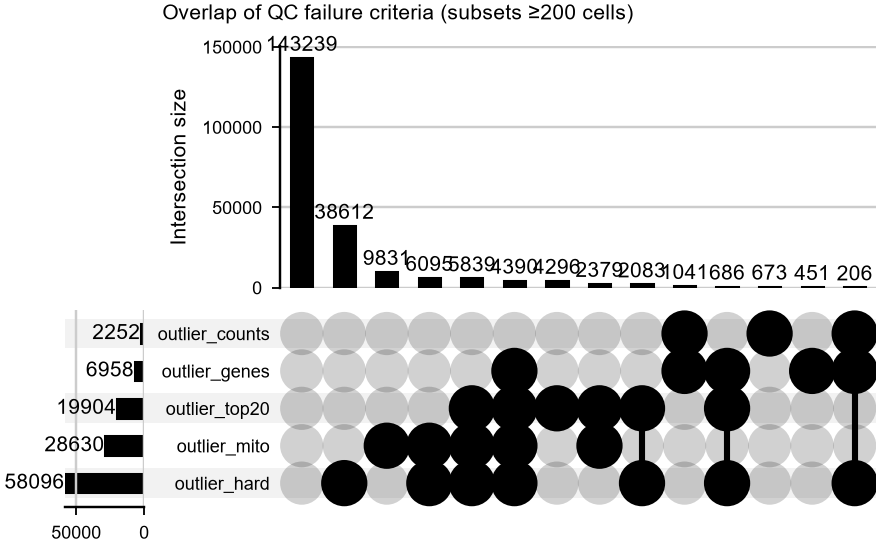

In [7]:
fig = plt.figure(figsize=figsize(120, 70))
UpSet(from_indicators(flag_cols, data=adata.obs[flag_cols]), subset_size="count", show_counts=True,
      sort_by="cardinality", min_subset_size=200, element_size=None).plot(fig=fig)
fig.suptitle("Overlap of QC failure criteria (subsets ≥200 cells)", fontsize=7)
save_figure(fig, "S2_qc_failure_upset", FIG)
plt.show()

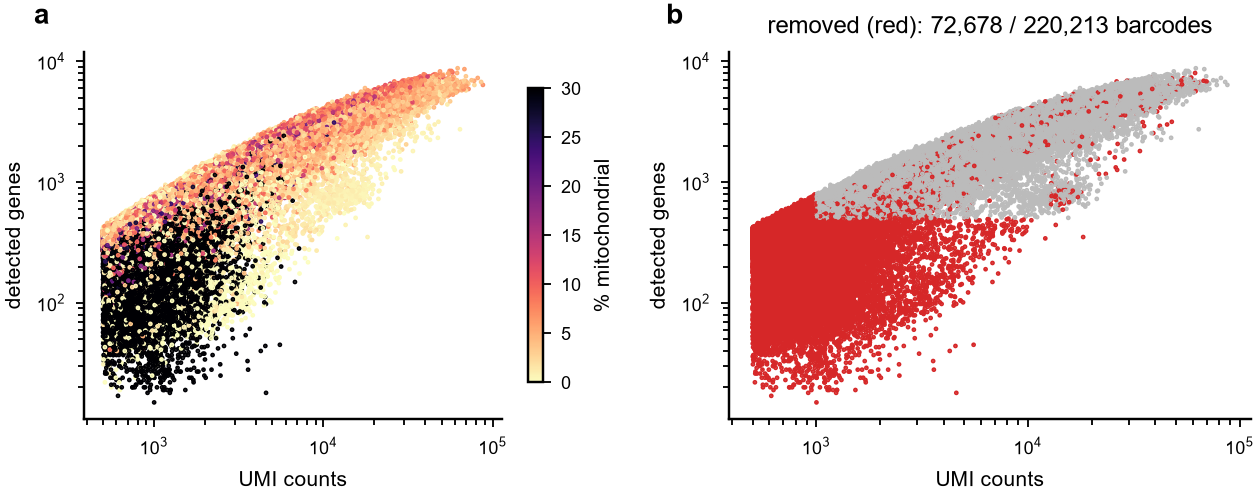

In [8]:
fig, axes = plt.subplots(1, 2, figsize=figsize(150, 62))
o = adata.obs.sample(frac=1, random_state=0)
ax = axes[0]
sca = ax.scatter(o["total_counts"], o["n_genes_by_counts"], c=o["pct_counts_mt"], s=0.3, cmap="magma_r",
                 vmax=30, rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("UMI counts"); ax.set_ylabel("detected genes")
plt.colorbar(sca, ax=ax, label="% mitochondrial", shrink=0.8)
panel_label(ax, "a")
ax = axes[1]
ax.scatter(o["total_counts"], o["n_genes_by_counts"], c=np.where(o["qc_fail"], "#D62728", "#BBBBBB"),
           s=0.3, rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("UMI counts"); ax.set_ylabel("detected genes")
ax.set_title(f"removed (red): {int(o['qc_fail'].sum()):,} / {len(o):,} barcodes")
panel_label(ax, "b")
fig.tight_layout()
save_figure(fig, "S2_qc_scatter_counts_genes_mito", FIG)
plt.show()

## 4. Filter cells and libraries

In [9]:
n0 = adata.n_obs
adata = adata[~adata.obs["qc_fail"]].copy()
per_lib = adata.obs["library_id"].value_counts()
small = per_lib[per_lib < QC["min_cells_per_library"]].index.tolist()
if small:
    log.warning(f"libraries below {QC['min_cells_per_library']} cells after QC are removed: {small}")
    adata = adata[~adata.obs["library_id"].isin(small)].copy()
adata.obs["library_id"] = adata.obs["library_id"].cat.remove_unused_categories()
print(f"{n0:,} -> {adata.n_obs:,} cells after QC ({100 * adata.n_obs / n0:.1f} % kept)")
adata.layers["counts"] = adata.X.copy()

220,213 -> 147,535 cells after QC (67.0 % kept)


## 5. Doublet detection
**scDblFinder** generates artificial doublets by summing random pairs of cells
within each library and trains a gradient-boosted tree classifier to separate
them from real droplets using kNN-based features; it was among the most
accurate methods in an independent benchmark (Xi & Li 2021, *Cell Systems*).
**Scrublet** uses a similar simulation idea with a kNN doublet score. Doublets
can only form *within* a 10x channel, so both run per library.

In [10]:
dbl_r = doublets.run_scdblfinder(adata, rscript(cfg), P.r_scripts / "scdblfinder.R", P.interim / "scdblfinder",
                                 batch_key="library_id", threads=8)
dbl_py = doublets.run_scrublet(adata, batch_key="library_id",
                               expected_rate=cfg["doublets"]["scrublet_expected_rate"])
adata.obs = adata.obs.join(dbl_r).join(dbl_py)
adata.obs["scrublet_doublet"] = adata.obs["scrublet_doublet"].fillna(False).astype(bool)
tab = doublets.concordance(adata.obs)
write_table(tab, TAB / "doublet_concordance")
tab

02:44:54 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\scdblfinder.R J:\Portfolio_projects\Projects\scRNA\data\interim\scdblfinder\counts_for_scdblfinder.h5 J:\Portfolio_projects\Projects\scRNA\data\interim\scdblfinder\scdblfinder_calls.csv 8


02:57:08 | INFO | R finished: scdblfinder.R
loaded 33694 genes x 147535 cells from 43 libraries
Warning message:
<anonymous>: ... may be used in an incorrect context: 
     scDblFinder(sce[sel_features, x], clusters = clusters, dims = dims, 
         dbr = dbr, dbr.sd = dbr.sd, dbr.per1k = dbr.per1k, clustCor = clustCor, 
         unident.th = unident.th, knownDoublets = knownDoublets, knownUse = knownUse, 
         artificialDoublets = artificialDoublets, k = k, processing = processing, 
         nfeatures = nfeatures, propRandom = propRandom, includePCs = includePCs, 
         propMarkers = propMarkers, trainingFeatures = trainingFeatures, 
         returnType = ifelse(returnType == "counts", "counts", "table"), 
         threshold = isSplitMode, score = ifelse(isSplitMode, score, 
             "weighted"), removeUnidentifiable = removeUnidentifiable, 
         verbose = FALSE, aggregateFeatures = aggregateFeatures, ...)
 
doublets called: 11098 / 147535 (7.5 %)


03:03:32 | INFO | doublet call Jaccard (scDblFinder vs Scrublet): 0.10


Scrublet,False,True
scDblFinder,,
False,136186,251
True,9975,1123


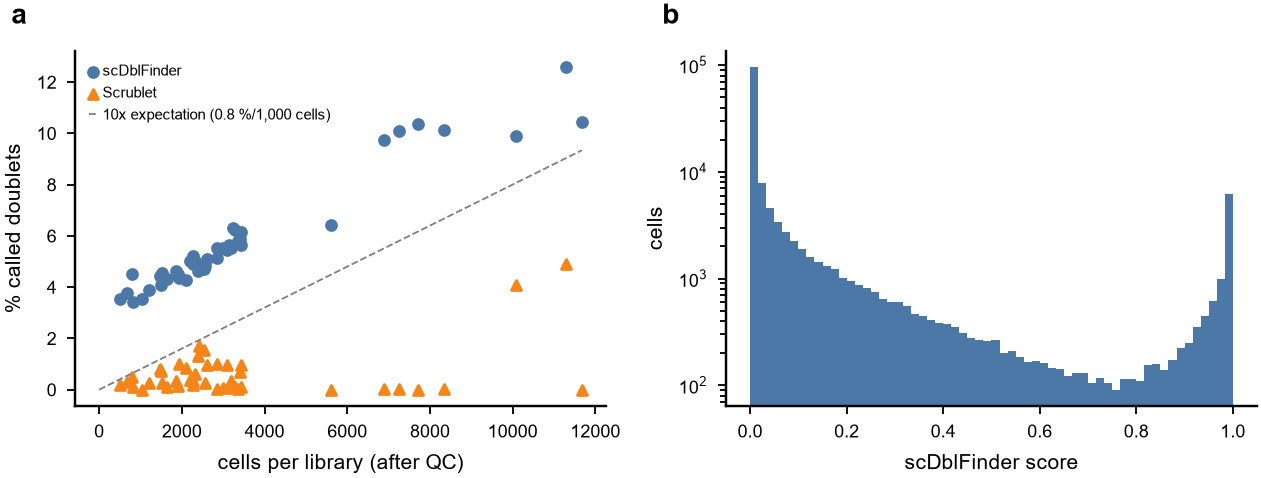

In [11]:
rate = adata.obs.groupby("library_id", observed=True).agg(
    n_cells=("library_id", "size"),
    scDblFinder=("scDblFinder_doublet", "mean"),
    Scrublet=("scrublet_doublet", "mean"))
rate[["scDblFinder", "Scrublet"]] *= 100
write_table(rate.round(2), TAB / "doublet_rate_per_library")

fig, axes = plt.subplots(1, 2, figsize=figsize(150, 60))
ax = axes[0]
ax.scatter(rate["n_cells"], rate["scDblFinder"], s=10, label="scDblFinder", color="#4C78A8")
ax.scatter(rate["n_cells"], rate["Scrublet"], s=10, label="Scrublet", color="#F58518", marker="^")
xs = np.linspace(0, rate["n_cells"].max(), 50)
ax.plot(xs, 0.8 * xs / 1000, ls="--", color="grey", lw=0.6, label="10x expectation (0.8 %/1,000 cells)")
ax.set_xlabel("cells per library (after QC)")
ax.set_ylabel("% called doublets")
ax.legend(fontsize=5)
panel_label(ax, "a")
ax = axes[1]
ax.hist(adata.obs["scDblFinder_score"], bins=60, color="#4C78A8")
ax.set_yscale("log")
ax.set_xlabel("scDblFinder score")
ax.set_ylabel("cells")
panel_label(ax, "b")
fig.tight_layout()
save_figure(fig, "S2_doublet_rates", FIG)
plt.show()

**Decision:** remove scDblFinder doublets (primary method). Scrublet is reported
for transparency; a final, biology-based doublet check (clusters co-expressing
two lineage programmes) is done after clustering in Notebook 05.

In [12]:
n1 = adata.n_obs
adata = adata[~adata.obs["scDblFinder_doublet"]].copy()
print(f"{n1:,} -> {adata.n_obs:,} cells after doublet removal")

147,535 -> 136,437 cells after doublet removal


## 6. Gene filter

In [13]:
sc.pp.filter_genes(adata, min_cells=QC["min_cells_per_gene"])
print(adata)

AnnData object with n_obs × n_vars = 136437 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'


## 7. Comparison with the authors' QC
How similar is our cell set to the 114,396 cells retained by Habermann *et al.*?

In [14]:
kept = pd.Series(True, index=adata.obs_names)
raw_obs = sc.read_h5ad(P.interim / "discovery_raw.h5ad", backed="r").obs
cmp = pd.DataFrame({"ours": raw_obs.index.isin(kept.index), "authors": raw_obs["author_qc_pass"].values},
                   index=raw_obs.index)
ct = pd.crosstab(cmp["ours"], cmp["authors"], rownames=["kept (this study)"], colnames=["kept (authors)"])
write_table(ct, TAB / "qc_overlap_with_authors")
ct

kept (authors),False,True
kept (this study),,
False,71236,12540
True,34581,101856


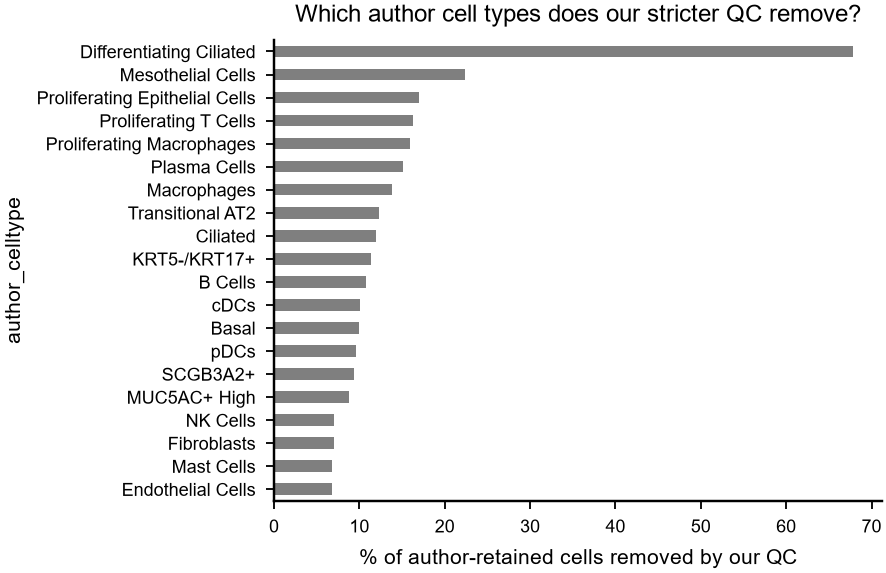

author_celltype
Differentiating Ciliated          67.8
Mesothelial Cells                 22.3
Proliferating Epithelial Cells    17.0
Proliferating T Cells             16.3
Proliferating Macrophages         15.9
Plasma Cells                      15.1
Macrophages                       13.8
Transitional AT2                  12.2
Ciliated                          11.9
KRT5-/KRT17+                      11.3
B Cells                           10.8
cDCs                              10.0
Basal                             10.0
pDCs                               9.6
SCGB3A2+                           9.4
Name: count, dtype: float64

In [15]:
lost = raw_obs.loc[cmp["authors"] & ~cmp["ours"], "author_celltype"].value_counts()
frac = (lost / raw_obs.loc[cmp["authors"], "author_celltype"].value_counts()).dropna().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=figsize(90, 70))
frac.head(20).iloc[::-1].plot.barh(ax=ax, color="#7F7F7F")
ax.set_xlabel("% of author-retained cells removed by our QC")
ax.set_title("Which author cell types does our stricter QC remove?")
save_figure(fig, "S2_qc_removed_by_author_celltype", FIG)
plt.show()
frac.round(1).head(15)

## 8. Final QC summary and save

In [16]:
write_table(qc.qc_summary(adata), TAB / "qc_metrics_per_library_after")
summary = pd.Series({
    "barcodes (Cell Ranger)": n0,
    "after MAD/hard QC": n1,
    "after doublet removal": adata.n_obs,
    "genes kept": adata.n_vars,
    "libraries": adata.obs.library_id.nunique(),
    "donors": adata.obs.donor_id.nunique(),
})
write_table(summary.to_frame("value"), TAB / "qc_cell_flow")
adata.write_h5ad(P.interim / "discovery_qc.h5ad", compression="lzf")
summary

barcodes (Cell Ranger)    220213
after MAD/hard QC         147535
after doublet removal     136437
genes kept                 24723
libraries                     43
donors                        30
dtype: int64